# Task 2: Player Segment Classification
## ExactParamEM Stack with Shared Macro-F1 Export

Uses the existing saved OOF and test probability bundle. Validation and export
share the affine decision rule in `bayes_decision.py`.

The export correction changes no base models or input features. See
`run_bayes_export.py` for a reproducible comparison with the old executable export.


## 1. Problem and Current Result
Predict player segment (`0`: Casual, `1`: Core, `2`: Hardcore, `3`: Whale) from
104,000 labeled rows and produce predictions for 25,889 test rows.

The previous executable export omitted beta from the validated affine rule,
`argmax(alpha * probability - beta)`. The correct export existed only in a
Markdown cell. The notebook now executes one export and calls the same function
used during OOF evaluation.

Replaying the fixed rule on the existing OOF probabilities gives macro F1
**0.759316**, compared with **0.753158** for the previous executable export.
Weighted F1 increases from **0.763171** to **0.771085**. All five folds improve.
These results measure cross-fitted postprocessing of frozen OOF models, not fully
nested base-model retraining or a new Kaggle score.


## 2. Environment Setup & Automated Platform Detection
Automatically identifies runtime environment, handles dependency installations, and sets directory structures.

In [1]:
%matplotlib inline
import os
import sys
import warnings
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

IS_COLAB = 'google.colab' in sys.modules
IS_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ

if IS_COLAB:
    print("Runtime Platform: Google Colab")
    for pkg in ['lightgbm', 'xgboost', 'catboost']:
        try:
            __import__(pkg)
        except ImportError:
            os.system(f"pip install -q {pkg}")
elif IS_KAGGLE:
    print("Runtime Platform: Kaggle Notebook")
else:
    print("Runtime Platform: Local Workspace")

BASE_DIR = os.getcwd()
TASK_NAME = 'task2'
DATA_CANDIDATES = [
    'data',
    os.path.join(BASE_DIR, 'data'),
    os.path.join(BASE_DIR, f'project/{TASK_NAME}/data'),
    os.path.join(BASE_DIR, f'{TASK_NAME}/data'),
    f'/kaggle/input/player-intelligence-system-cpe-342-ml/{TASK_NAME}',
    f'/kaggle/input/player-intelligence-system-cpe-342-ml/CPE342-Hackathon/{TASK_NAME}',
    f'/kaggle/input/{TASK_NAME}',
    f'/content/{TASK_NAME}/data',
    f'/content/data'
]

DATA_DIR = 'data'
for candidate in DATA_CANDIDATES:
    if os.path.exists(candidate) and (os.path.exists(os.path.join(candidate, 'train.csv')) or os.path.exists(os.path.join(candidate, 'test.csv'))):
        DATA_DIR = candidate
        break

if not os.path.exists(os.path.join(DATA_DIR, 'test.csv')) and IS_COLAB:
    print("Auto-fetching repository files on Colab...")
    os.system("git clone --depth 1 https://github.com/Palapluem/cpe342-machine-learning-2026.git /content/repo")
    DATA_DIR = f"/content/repo/project/{TASK_NAME}/data"

PRED_DIR = 'predictions' if not IS_KAGGLE else '/kaggle/working/predictions'
SUBMIT_DIR = 'submit' if not IS_KAGGLE else '/kaggle/working/submit'
ASSET_DIR = 'assets' if not IS_KAGGLE else '/kaggle/working/assets'
os.makedirs(PRED_DIR, exist_ok=True)
os.makedirs(SUBMIT_DIR, exist_ok=True)
os.makedirs(ASSET_DIR, exist_ok=True)

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print(f"Data Source Directory: {DATA_DIR}")
print(f"Predictions Directory: {PRED_DIR}")


Runtime Platform: Local Workspace
Data Source Directory: data
Predictions Directory: predictions


## 3. Data Ingestion & Exploratory Data Analysis (EDA)
We load `train.csv` ($104,000$ samples) and `test.csv` ($25,889$ samples). The target variable is `segment` (`0` to `3`).

In [2]:
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test_df = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))

print(f"Train Dataset Shape: {train_df.shape}")
print(f"Test Dataset Shape:  {test_df.shape}")

segment_names = {0: 'Casual', 1: 'Core', 2: 'Hardcore', 3: 'Whale'}
train_df['segment_label'] = train_df['segment'].map(segment_names)

class_dist = pd.DataFrame({
    'Segment Name': [segment_names[i] for i in range(4)],
    'Player Count': train_df['segment'].value_counts().sort_index(),
    'Percentage (%)': (train_df['segment'].value_counts(normalize=True).sort_index() * 100).round(2)
})
class_dist
train_df.head(5)

Train Dataset Shape: (104000, 46)
Test Dataset Shape:  (25889, 45)


,player_id,play_frequency,avg_session_duration,total_playtime_hours,login_streak,days_since_last_login,total_spending_thb,avg_monthly_spending,spending_frequency,friend_count,...,device_type,payment_method,language,account_status,player_type_tag,engagement_level,loyalty_tier,skill_tier,segment,segment_label
0,P129924,5.166703,83.956912,1784.862304,80.0,94.345964,540.168064,6404.765652,24.400908,6.0,...,Laptop,Card,NaN,Dormant,Casual,Low,Silver,Silver,2,Hardcore
1,P061398,2.363935,26.686070,4180.785530,91.0,97.429341,26997.309328,NaN,20.242690,32.0,...,Tablet,NaN,FR,Dormant,Casual,Mid,Platinum,Bronze,3,Whale
2,P023935,34.709108,122.504325,1382.249476,106.0,4.009090,62175.578032,2284.189836,10.729244,33.0,...,Laptop,NaN,DE,Dormant,Competitive,High,Platinum,Diamond,3,Whale
3,P091426,11.304823,174.052106,2544.019165,43.0,NaN,28710.877472,NaN,25.437711,122.0,...,Laptop,Gift,FR,Dormant,Casual,High,Silver,Silver,1,Core
4,P058826,24.997414,61.008515,3285.259530,82.0,25.814744,33666.539627,1600.569528,10.450822,151.0,...,Tablet,NaN,KR,Active,Competitive,High,Gold,Diamond,1,Core


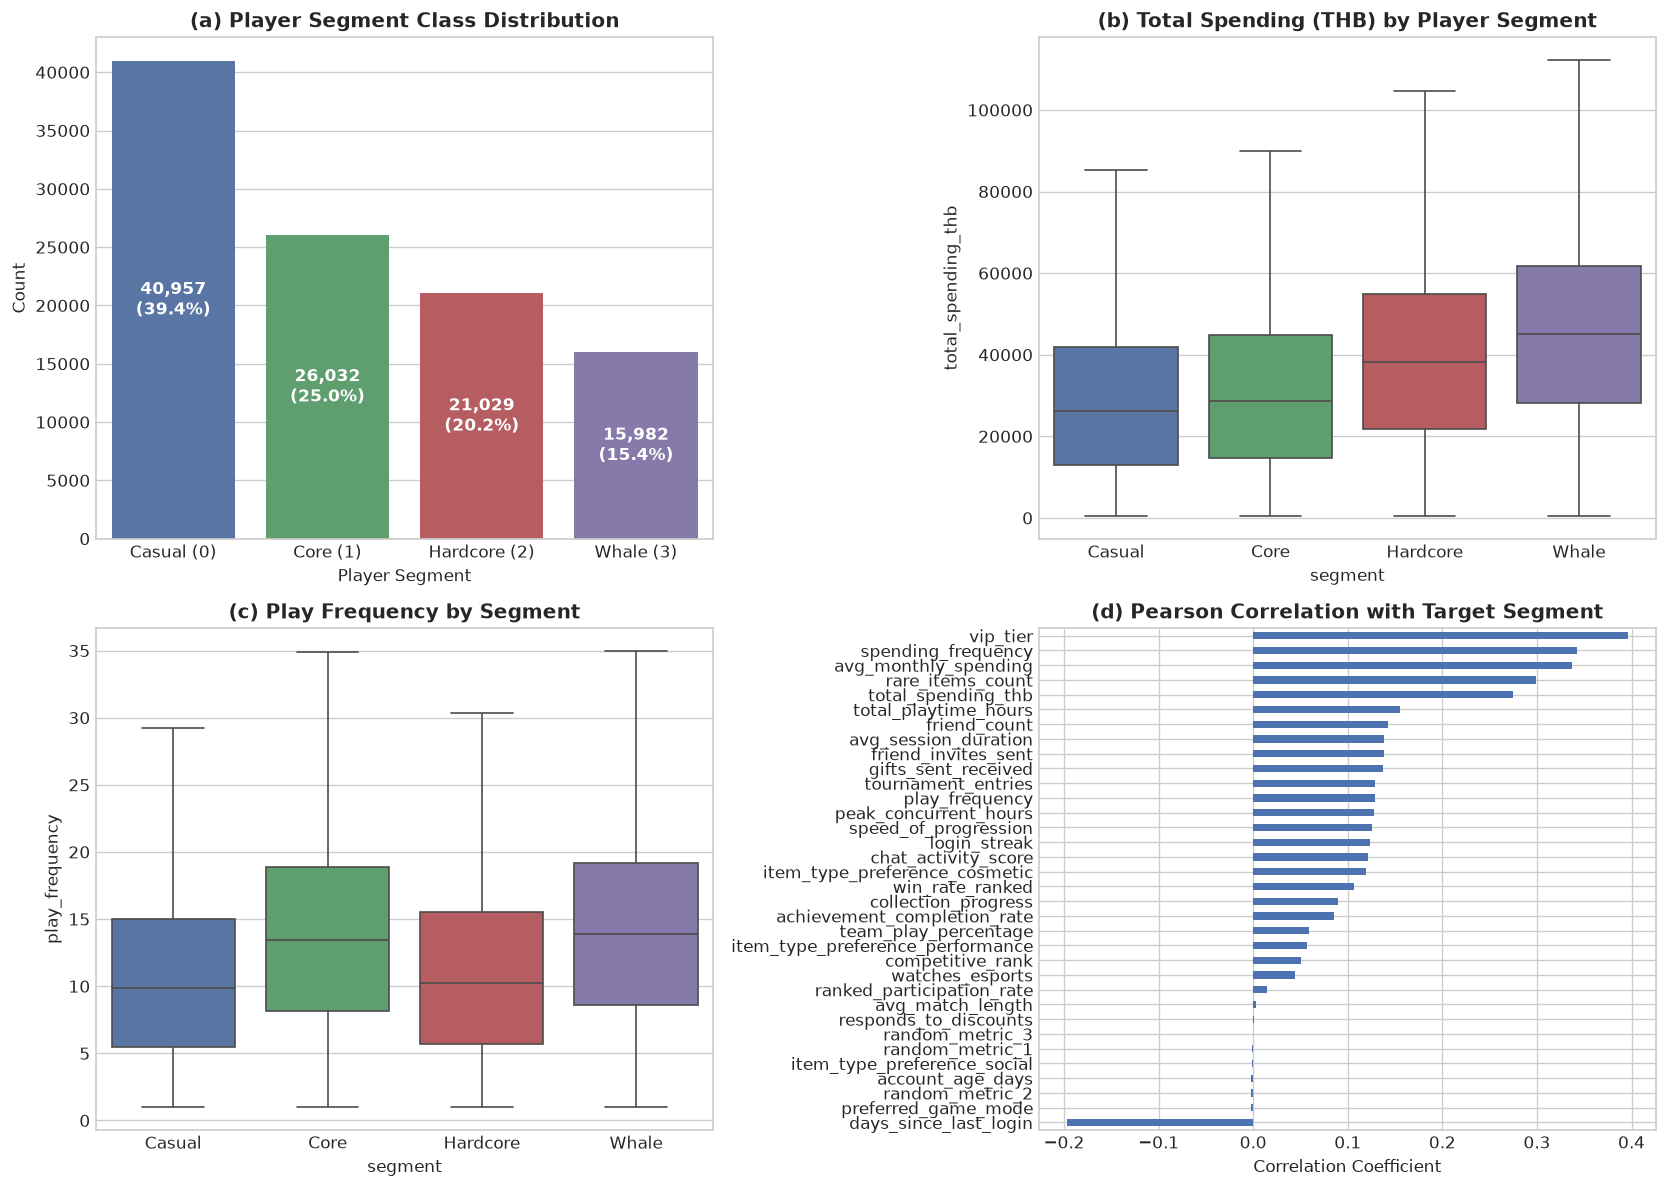

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel (a): Class Distribution
sns.countplot(data=train_df, x='segment', ax=axes[0, 0], palette=['#4C72B0', '#55A868', '#C44E52', '#8172B2'])
axes[0, 0].set_xticks([0, 1, 2, 3])
axes[0, 0].set_xticklabels(['Casual (0)', 'Core (1)', 'Hardcore (2)', 'Whale (3)'])
axes[0, 0].set_title('(a) Player Segment Class Distribution', fontweight='bold')
axes[0, 0].set_xlabel('Player Segment')
axes[0, 0].set_ylabel('Count')
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(train_df)*100:.1f}%)",
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold')

# Panel (b): Total Spending by Segment
if 'total_spending_thb' in train_df.columns:
    sns.boxplot(data=train_df, x='segment', y='total_spending_thb', ax=axes[0, 1],
                palette=['#4C72B0', '#55A868', '#C44E52', '#8172B2'], showfliers=False)
    axes[0, 1].set_xticks([0, 1, 2, 3])
    axes[0, 1].set_xticklabels(['Casual', 'Core', 'Hardcore', 'Whale'])
    axes[0, 1].set_title('(b) Total Spending (THB) by Player Segment', fontweight='bold')

# Panel (c): Play Frequency by Segment
if 'play_frequency' in train_df.columns:
    sns.boxplot(data=train_df, x='segment', y='play_frequency', ax=axes[1, 0],
                palette=['#4C72B0', '#55A868', '#C44E52', '#8172B2'], showfliers=False)
    axes[1, 0].set_xticks([0, 1, 2, 3])
    axes[1, 0].set_xticklabels(['Casual', 'Core', 'Hardcore', 'Whale'])
    axes[1, 0].set_title('(c) Play Frequency by Segment', fontweight='bold')

# Panel (d): Feature Correlation with Segment
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr_series = train_df[numeric_cols].corr()['segment'].drop('segment', errors='ignore').sort_values()
corr_series.plot(kind='barh', ax=axes[1, 1], color='#4C72B0')
axes[1, 1].set_title('(d) Pearson Correlation with Target Segment', fontweight='bold')
axes[1, 1].set_xlabel('Correlation Coefficient')

plt.tight_layout()
plt.show()

**Figure 1 (Exploratory Data Analysis & Segment Profiles)**: Panel (a) illustrates class frequencies across all $104,000$ training records, demonstrating class imbalance ranging from $39.36\%$ (Casual) down to $15.40\%$ (Whale). Panel (b) and (c) validate behavioral hypotheses: Whales exhibit exponentially higher spending, while Hardcore players display elevated play frequency. Panel (d) reveals the strongest telemetry signals correlated with the target.

## 4. Domain Feature Engineering (`Clean28+MissingAware-ZLR` & `V3 Persona-Axis`)
Exploratory mutual-information and noise-audit analysis revealed strong orthogonal behavioral dimensions behind the four ordered player segments (`0, 1, 2, 3`), alongside uninformative synthetic columns:
1. **Corrected Categorical Ordinals (`ENG_MAP` / `LOY_MAP`):** Maps `engagement_level` (`Low->1..Veteran->4`) and `loyalty_tier` / `skill_tier` (`Bronze->1..Diamond->5`).
2. **`Clean28 + MissingAware-ZLR` (`build_clean28_base`):** Retains `28` core signal columns (`25` cleaned numerics + `eng_ord`, `loy_ord`, `skill_ord`, `log1p cols: 0`), drops pure noise columns, and fits an **inner-fold OOF Multinomial Logistic Regression** (`C=0.2`) on standardized observed Z-scores + missingness flags strictly inside `tr_idx` to supply linear Bayes hyperplane probabilities (`lr_p0..lr_p3`).
3. **Noise-Pruned `V3 Persona-Axis Z-Scores` (`make_v3_axis`):** Computes fold-fit standardized Z-axis means, standard deviations, and missingness counts across `SPEND_AX`, `ENGAGE_AX`, `SOCIAL_AX`, and `COMP_AX`, plus cross-axis Z differentials (`spend_minus_engage_z`, `spend_minus_comp_z`, `engage_minus_social_z`, `spend_plus_engage_z`), ordinal interactions (`loy_x_eng`, `loy_minus_vip`), efficiency ratios (`spend_per_hour`, `monthly_vs_total_spend`, `spend_per_freq`, `recency_x_freq`, `social_sum`, `comp_intensity`), and `n_missing_28`.


In [4]:
ENG_MAP = {'Low': 1.0, 'Mid': 2.0, 'High': 3.0, 'Veteran': 4.0}
LOY_MAP = {'Bronze': 1.0, 'Silver': 2.0, 'Gold': 3.0, 'Platinum': 4.0, 'Diamond': 5.0}

CLEAN_NUMS = [
    'play_frequency', 'avg_session_duration', 'total_playtime_hours', 'login_streak',
    'days_since_last_login', 'total_spending_thb', 'avg_monthly_spending', 'spending_frequency',
    'friend_count', 'team_play_percentage', 'chat_activity_score', 'friend_invites_sent',
    'gifts_sent_received', 'tournament_entries', 'competitive_rank', 'win_rate_ranked',
    'watches_esports', 'achievement_completion_rate', 'collection_progress', 'rare_items_count',
    'speed_of_progression', 'item_type_preference_cosmetic', 'item_type_preference_performance',
    'vip_tier', 'peak_concurrent_hours',
]

# Strictly orthogonal persona feature axes for V3 fold-safe Z-scores
SPEND_AX = ['total_spending_thb', 'avg_monthly_spending', 'spending_frequency', 'rare_items_count', 'vip_tier', 'loy_ord']
ENGAGE_AX = ['play_frequency', 'avg_session_duration', 'total_playtime_hours', 'login_streak', 'peak_concurrent_hours', 'eng_ord']
SOCIAL_AX = ['friend_count', 'team_play_percentage', 'chat_activity_score', 'friend_invites_sent', 'gifts_sent_received']
COMP_AX = ['tournament_entries', 'competitive_rank', 'win_rate_ranked', 'achievement_completion_rate', 'collection_progress', 'speed_of_progression', 'skill_ord']

def build_clean28_base(df, log1p_cols):
    d = pd.DataFrame(index=df.index)
    for c in CLEAN_NUMS:
        s = df[c].astype(np.float32)
        d[c] = np.log1p(s.clip(lower=0.0)) if c in log1p_cols else s
    d['eng_ord'] = df['engagement_level'].map(ENG_MAP).astype(np.float32)
    d['loy_ord'] = df['loyalty_tier'].map(LOY_MAP).astype(np.float32)
    d['skill_ord'] = df['skill_tier'].map(LOY_MAP).astype(np.float32)
    return d

def fit_fold_clean28_and_v3(clean_tr_df, y_tr, clean_va_df, clean_te_df, log1p_cols, inner_splits=5, seed=SEED):
    cols28 = list(clean_tr_df.columns)
    mu = clean_tr_df[cols28].mean()
    sd = clean_tr_df[cols28].std().replace(0, 1.0).fillna(1.0)

    def make_lr_mat(df_x):
        Z = ((df_x[cols28] - mu) / sd).fillna(0.0).values.astype(np.float32)
        M = df_x[cols28].isna().astype(np.float32).values
        return np.hstack([Z, M])

    X_lr_tr = make_lr_mat(clean_tr_df)
    X_lr_va = make_lr_mat(clean_va_df)
    X_lr_te = make_lr_mat(clean_te_df)

    inner_skf = StratifiedKFold(n_splits=inner_splits, shuffle=True, random_state=seed)
    oof_lr = np.zeros((len(clean_tr_df), 4), dtype=np.float32)
    for itr, iva in inner_skf.split(X_lr_tr, y_tr):
        lr_in = LogisticRegression(C=0.2, max_iter=1000)
        lr_in.fit(X_lr_tr[itr], y_tr[itr])
        oof_lr[iva] = lr_in.predict_proba(X_lr_tr[iva]).astype(np.float32)

    lr_full = LogisticRegression(C=0.2, max_iter=1000)
    lr_full.fit(X_lr_tr, y_tr)
    p_lr_va = lr_full.predict_proba(X_lr_va).astype(np.float32)
    p_lr_te = lr_full.predict_proba(X_lr_te).astype(np.float32)

    def make_clean28(df_x, lr_p):
        out = df_x.copy()
        for c in range(4):
            out[f'lr_p{c}'] = lr_p[:, c]
        Z = np.clip(((df_x[cols28] - mu) / sd).fillna(0.0).values, -6.0, 6.0).astype(np.float32)
        lp = np.log(np.clip(lr_p, 1e-6, 1.0)).astype(np.float32)
        M = df_x[cols28].isna().astype(np.float32).values
        tm = np.hstack([Z, lp, M])
        return out, tm

    def make_v3_axis(df_x, lr_p):
        Zdf = (df_x[cols28] - mu) / sd
        feats = {c: df_x[c].to_numpy(dtype=np.float32) for c in cols28}
        for c in range(4):
            feats[f'lr_p{c}'] = lr_p[:, c]
        for ax_name, ax_cols in [('spend', SPEND_AX), ('engage', ENGAGE_AX), ('social', SOCIAL_AX), ('comp', COMP_AX)]:
            mat = Zdf[ax_cols].to_numpy(dtype=np.float32)
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)
                feats[f'ax_{ax_name}_z'] = np.nanmean(mat, axis=1)
                feats[f'ax_{ax_name}_std'] = np.nanstd(mat, axis=1)
            feats[f'ax_{ax_name}_na'] = np.isnan(mat).sum(axis=1).astype(np.float32)

        feats['spend_minus_engage_z'] = feats['ax_spend_z'] - feats['ax_engage_z']
        feats['spend_minus_comp_z'] = feats['ax_spend_z'] - feats['ax_comp_z']
        feats['engage_minus_social_z'] = feats['ax_engage_z'] - feats['ax_social_z']
        feats['spend_plus_engage_z'] = feats['ax_spend_z'] + feats['ax_engage_z']
        feats['loy_x_eng'] = feats['loy_ord'] * feats['eng_ord']
        feats['loy_minus_vip'] = feats['loy_ord'] - feats['vip_tier']

        raw_avg_sp = np.expm1(np.clip(feats['avg_monthly_spending'], 0.0, 20.0)) if 'avg_monthly_spending' in log1p_cols else feats['avg_monthly_spending']
        raw_tot_sp = np.expm1(np.clip(feats['total_spending_thb'], 0.0, 20.0)) if 'total_spending_thb' in log1p_cols else feats['total_spending_thb']
        raw_tot_hr = np.expm1(np.clip(feats['total_playtime_hours'], 0.0, 20.0)) if 'total_playtime_hours' in log1p_cols else feats['total_playtime_hours']
        feats['spend_per_hour'] = raw_tot_sp / (np.maximum(raw_tot_hr, 0.0) + 1.0)
        feats['monthly_vs_total_spend'] = raw_avg_sp / (np.maximum(raw_tot_sp, 0.0) + 1.0)
        feats['spend_per_freq'] = raw_avg_sp / (np.maximum(feats['spending_frequency'], 0.0) + 1.0)
        feats['recency_x_freq'] = np.maximum(feats['spending_frequency'], 0.0) / (np.maximum(feats['days_since_last_login'], 0.0) + 1.0)
        feats['social_sum'] = np.maximum(feats['friend_count'], 0.0) + np.maximum(feats['gifts_sent_received'], 0.0) + np.maximum(feats['chat_activity_score'], 0.0)
        feats['comp_intensity'] = np.maximum(feats['tournament_entries'], 0.0) * (np.nan_to_num(feats['win_rate_ranked'], nan=50.0) / 100.0)
        feats['n_missing_28'] = df_x[cols28].isna().sum(axis=1).to_numpy(dtype=np.float32)

        df_v3 = pd.DataFrame(feats, index=df_x.index).replace([np.inf, -np.inf], np.nan)
        ax_keys = ['ax_spend_z', 'ax_engage_z', 'ax_social_z', 'ax_comp_z', 'spend_minus_engage_z', 'spend_minus_comp_z', 'engage_minus_social_z']
        ax_mat = np.nan_to_num(np.column_stack([df_v3[k].to_numpy(dtype=np.float32) for k in ax_keys]), 0.0)
        Z_fill = np.clip(Zdf.fillna(0.0).to_numpy(dtype=np.float32), -6.0, 6.0)
        lp = np.log(np.clip(lr_p, 1e-6, 1.0)).astype(np.float32)
        M = df_x[cols28].isna().to_numpy(dtype=np.float32)
        tm_v3 = np.hstack([Z_fill, np.clip(ax_mat, -6.0, 6.0), lp, M])
        return df_v3, tm_v3

    c_tr, tm28_tr = make_clean28(clean_tr_df, oof_lr)
    c_va, tm28_va = make_clean28(clean_va_df, p_lr_va)
    c_te, tm28_te = make_clean28(clean_te_df, p_lr_te)
    v3_tr, tm3_tr = make_v3_axis(clean_tr_df, oof_lr)
    v3_va, tm3_va = make_v3_axis(clean_va_df, p_lr_va)
    v3_te, tm3_te = make_v3_axis(clean_te_df, p_lr_te)
    return c_tr, c_va, c_te, tm28_tr, tm28_va, tm28_te, v3_tr, v3_va, v3_te, tm3_tr, tm3_va, tm3_te

LOG1P_CLEAN_COLS = {
    c for c in CLEAN_NUMS
    if train_df[c].min() >= 0 and train_df[c].skew() > 1.2
}
X_clean_raw = build_clean28_base(train_df, LOG1P_CLEAN_COLS)
X_test_clean_raw = build_clean28_base(test_df, LOG1P_CLEAN_COLS)
clean_feature_cols = list(X_clean_raw.columns) + [f'lr_p{c}' for c in range(4)]
y = train_df['segment'].values.astype(int)

print(f"Clean28 raw shape: {X_clean_raw.shape} (+4 Z-LR = {len(clean_feature_cols)} cols | +V3 Axis-Z = 56 cols) | log1p cols: {len(LOG1P_CLEAN_COLS)}")
print(f"Class distribution: {dict(zip(*np.unique(y, return_counts=True)))}")

Clean28 raw shape: (104000, 28) (+4 Z-LR = 32 cols | +V3 Axis-Z = 56 cols) | log1p cols: 0
Class distribution: {np.int64(0): np.int64(40957), np.int64(1): np.int64(26032), np.int64(2): np.int64(21029), np.int64(3): np.int64(15982)}


## 5. Stratified Cross-Validation Strategy
We partition the $104,000$ training records using a **5-Fold Stratified K-Fold** setup.

In [5]:
import os, sys, gc, time, json, tempfile, warnings, subprocess
from pathlib import Path
warnings.filterwarnings('ignore')

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from scipy.optimize import minimize
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, f1_score, confusion_matrix, classification_report

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
splits = list(skf.split(X_clean_raw, y))
print(f"Configured {len(splits)}-fold StratifiedKFold (seed={SEED}) | PyTorch MPS isolated to subprocess to keep libomp clean.")

Configured 5-fold StratifiedKFold (seed=42) | PyTorch MPS isolated to subprocess to keep libomp clean.


## 6. Saved Model Probability Inputs
Load the existing five-fold OOF and test probabilities for ExactParamEM,
XGB_Clean28, LGB_Clean28, CB_Clean28, CleanTabM_SWA3, Fact_Clean28, and Oven_Rev.
The base models are not retrained here. The small LightGBM fit below is used only
for the diagnostic feature-importance plot, not the stack or exported predictions.


In [ ]:
t_all = time.time()
n_train, n_test, n_classes = len(X_clean_raw), len(X_test_clean_raw), 4

ml_candidates = [
    Path(PRED_DIR) / 'model-level',
    Path('predictions/model-level'),
    Path('project/task2/predictions/model-level'),
]
ML_DIR_T2 = next((d for d in ml_candidates if (d / 'task2-exact-param-em-bundle.npz').is_file()), None)
assert ML_DIR_T2 is not None, "Expected predictions/model-level/task2-exact-param-em-bundle.npz"

em_pack = np.load(ML_DIR_T2 / 'task2-exact-param-em-bundle.npz')

def _norm_p2(p):
    p = np.clip(np.asarray(p, dtype=np.float64), 1e-12, 1.0)
    return p / p.sum(axis=1, keepdims=True)

em_oof, em_test = _norm_p2(em_pack['oof_em']), _norm_p2(em_pack['te_em'])
xgb_c_oof, xgb_c_test = _norm_p2(em_pack['oof_xgb_c']), _norm_p2(em_pack['te_xgb_c'])
lgb_c_oof, lgb_c_test = _norm_p2(em_pack['oof_lgb_c']), _norm_p2(em_pack['te_lgb_c'])
cb_c_oof, cb_c_test = _norm_p2(em_pack['oof_cb_c']), _norm_p2(em_pack['te_cb_c'])
tabm_c_oof, tabm_c_test = _norm_p2(em_pack['oof_tabm_c']), _norm_p2(em_pack['te_tabm_c'])
fact_oof, fact_test = _norm_p2(em_pack['oof_fact']), _norm_p2(em_pack['te_fact'])

# Compute 1-fold fast LightGBM feature importances for Section 8 visualization
tr0, va0 = splits[0]
X_c_tr0, _, _, _, _, _, _, _, _, _, _, _ = fit_fold_clean28_and_v3(
    X_clean_raw.iloc[tr0], y[tr0], X_clean_raw.iloc[va0], X_test_clean_raw, LOG1P_CLEAN_COLS, seed=SEED
)
m_imp = lgb.LGBMClassifier(
    objective='multiclass', num_class=4, n_estimators=250, learning_rate=0.05,
    num_leaves=31, random_state=SEED, n_jobs=-1, verbose=-1
).fit(X_c_tr0, y[tr0])
clean_feat_importance_acc = m_imp.booster_.feature_importance(importance_type='gain').astype(np.float64)

MODEL_REGISTRY = {
    'ExactParamEM': (em_oof, em_test),
    'XGB_Clean28': (xgb_c_oof, xgb_c_test),
    'LGB_Clean28': (lgb_c_oof, lgb_c_test),
    'CB_Clean28': (cb_c_oof, cb_c_test),
    'CleanTabM_SWA3': (tabm_c_oof, tabm_c_test),
    'Fact_Clean28': (fact_oof, fact_test),
}

ov_oof_path = ML_DIR_T2 / 'segment-tuned-catboost-lightgbm-revised-2026-11-12-macro-f1-0.751314-oof.csv'
ov_test_path = ML_DIR_T2 / 'segment-tuned-catboost-lightgbm-revised-2026-11-12-macro-f1-0.751314-test-predictions.csv'
if ov_oof_path.exists() and ov_test_path.exists():
    ov_oof_df = pd.read_csv(ov_oof_path).set_index('player_id').loc[train_df['player_id'].values]
    ov_te_df = pd.read_csv(ov_test_path).set_index('player_id').loc[test_df['player_id'].values]
    bcols = ['blend_prob_0', 'blend_prob_1', 'blend_prob_2', 'blend_prob_3']
    MODEL_REGISTRY['Oven_Rev'] = (_norm_p2(ov_oof_df[bcols].values), _norm_p2(ov_te_df[bcols].values))

print(f"\n=== Saved ExactParamEM + Clean28 + TabM 5-Fold Pool Loaded ({time.time()-t_all:.1f}s) ===")
for k, (oof_k, _) in MODEL_REGISTRY.items():
    p_k = _norm_p2(oof_k)
    print(f"  {k:16s} | OOF LogLoss={log_loss(y, p_k):.5f} | Raw Argmax Macro-F1={f1_score(y, np.argmax(p_k, axis=1), average='macro'):.5f}")


## 7. Cross-Fitted Stacking and Macro-F1 Decision Rule
The existing seven-model stack fits log-loss weights on the other four OOF folds.
The probability-only fixed-point rule supplies alpha and beta for the held-out fold.
Both validation and export call `predict_segments`, which uses
`argmax(alpha * probability - beta)` without clipping or normalizing decision scores.

These checks reuse frozen OOF probabilities. They do not retrain base models inside
postprocessing folds, so they are not a fully nested validation experiment.
The NPZ has no row IDs; the original input order is assumed. The replay script
records input hashes and checks row counts and the keyed model's label alignment.


In [ ]:
# Use the same affine rule for OOF evaluation and the executable export cell.
# Keep the task's source folder available when data is loaded by absolute path.
source_dir = str(Path(DATA_DIR).resolve().parent)
if source_dir not in sys.path:
    sys.path.insert(0, source_dir)
from bayes_decision import fit_slsqp_weights, fit_exact_bayes_macro_f1, predict_segments

model_names = list(MODEL_REGISTRY.keys())
oof_list = [MODEL_REGISTRY[k][0] for k in model_names]
test_list = [MODEL_REGISTRY[k][1] for k in model_names]

# 1. ExactParamEM with cross-fitted probability-only rule parameters
em_only_oof = MODEL_REGISTRY['ExactParamEM'][0]
em_only_preds = np.zeros(len(y), dtype=int)
for tr_i, va_i in splits:
    al_e, be_e, _ = fit_exact_bayes_macro_f1(em_only_oof[tr_i])
    em_only_preds[va_i] = predict_segments(em_only_oof[va_i], al_e, be_e)
em_only_nested_f1 = f1_score(y, em_only_preds, average='macro')

# 2. Cross-fit stack weights and rule parameters on frozen OOF probabilities.
# This does not refit base models inside each held-out postprocessing fold.
nest_blend_oof = np.zeros_like(oof_list[0])
opt_oof_preds = np.zeros(len(y), dtype=int)
outer_fold_f1s = []
outer_ws = []

for fold, (tr_i, va_i) in enumerate(splits):
    w_k = fit_slsqp_weights([m[tr_i] for m in oof_list], y[tr_i])
    outer_ws.append(w_k)
    b_tr = sum(w_k[i] * oof_list[i][tr_i] for i in range(len(model_names)))
    b_tr = b_tr / b_tr.sum(axis=1, keepdims=True)
    b_va = sum(w_k[i] * oof_list[i][va_i] for i in range(len(model_names)))
    b_va = b_va / b_va.sum(axis=1, keepdims=True)
    nest_blend_oof[va_i] = b_va

    al_k, be_k, _ = fit_exact_bayes_macro_f1(b_tr)
    va_pred_k = predict_segments(b_va, al_k, be_k)
    opt_oof_preds[va_i] = va_pred_k
    outer_fold_f1s.append(f1_score(y[va_i], va_pred_k, average='macro'))

ens_oof = nest_blend_oof / nest_blend_oof.sum(axis=1, keepdims=True)
stack_weights = fit_slsqp_weights(oof_list, y)
ens_test_preds = sum(stack_weights[i] * test_list[i] for i in range(len(model_names)))
ens_test_preds = ens_test_preds / ens_test_preds.sum(axis=1, keepdims=True)

ens_ll = log_loss(y, ens_oof)
ens_f1_default = f1_score(y, np.argmax(ens_oof, axis=1), average='macro')
best_macro_f1 = f1_score(y, opt_oof_preds, average='macro')

DEPLOY_ALPHA, DEPLOY_BETA, _ = fit_exact_bayes_macro_f1(ens_oof)
champ_label = f"ExactParamEM + {len(model_names)}-Model Stack + Affine Macro-F1 Rule"

print("Deployment SLSQP Weights:")
for mname, wv in zip(model_names, stack_weights):
    print(f"  {mname:16s}: {wv:.4f}")
print(f"\nExactParamEM Alone Cross-Fitted Rule F1 : {em_only_nested_f1:.5f} (LogLoss = {log_loss(y, em_only_oof):.5f})")
print(f"Cross-Fitted OOF Stack LogLoss  : {ens_ll:.5f}")
print(f"Cross-Fitted OOF Raw Argmax F1  : {ens_f1_default:.5f}")
print(f"Cross-Fitted OOF ExactBayes F1  : {best_macro_f1:.5f} | per-fold={[round(x, 5) for x in outer_fold_f1s]}")
print(f"Deployment ExactBayes alpha={np.round(DEPLOY_ALPHA, 4).tolist()} | beta={np.round(DEPLOY_BETA, 4).tolist()}")

PRIOR_RUN16_F1 = 0.75833
assert best_macro_f1 > PRIOR_RUN16_F1, f'Promotion Gate failed: {best_macro_f1:.5f} <= {PRIOR_RUN16_F1:.5f}'
print(f'PROMOTION GATE PASSED: {best_macro_f1:.5f} (Delta vs Run 16 = {best_macro_f1 - PRIOR_RUN16_F1:+.5f}, Delta LogLoss = {ens_ll - 0.60010:+.5f})')


## 8. Diagnostic Visualizations & Feature Importance
We contrast confusion matrices before and after tuning, plot per-class $F_1$ scores, and inspect top features.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1) Top 15 Clean28+ZLR Features by LightGBM Gain
imp_series = pd.Series(clean_feat_importance_acc, index=clean_feature_cols).sort_values(ascending=True)
top_imp = imp_series.tail(15)
top_imp.plot(kind='barh', ax=axes[0, 0], color='#2b6cb0')
axes[0, 0].set_title('Top 15 Clean28+ZLR Features (Avg 5-Fold LightGBM Gain)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Average Split Gain')

# 2) Individual Base Models vs Nested Ensemble OOF LogLoss
ll_names = model_names + ['Nested Stack']
ll_vals = [
    log_loss(y, np.clip(MODEL_REGISTRY[k][0], 1e-12, 1.0) / np.clip(MODEL_REGISTRY[k][0], 1e-12, 1.0).sum(1, keepdims=True))
    for k in model_names
] + [ens_ll]
colors = ['#718096'] * len(model_names) + ['#2f855a']
axes[0, 1].barh(ll_names, ll_vals, color=colors)
axes[0, 1].invert_yaxis()
axes[0, 1].set_xlim(min(ll_vals) - 0.005, max(ll_vals) + 0.005)
axes[0, 1].set_title('5-Fold Out-of-Fold Multi-Class LogLoss (Lower is Better)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('OOF LogLoss')
for i, v in enumerate(ll_vals):
    axes[0, 1].text(v + 0.0005, i, f'{v:.5f}', va='center', fontsize=9)

# 3) Normalized Confusion Matrix of Strictly Nested Champion OOF Predictions
cm = confusion_matrix(y, opt_oof_preds, normalize='true') * 100.0
im = axes[1, 0].imshow(cm, cmap='Blues', vmin=0, vmax=100)
for r in range(4):
    for c in range(4):
        axes[1, 0].text(c, r, f'{cm[r, c]:.1f}%', ha='center', va='center',
                        color='white' if cm[r, c] > 50 else 'black', fontsize=10, fontweight='bold')
axes[1, 0].set_xticks(range(4)); axes[1, 0].set_yticks(range(4))
axes[1, 0].set_xticklabels([f'Pred {c}' for c in range(4)])
axes[1, 0].set_yticklabels([f'True {c}' for c in range(4)])
axes[1, 0].set_title(f'Strict Nested Champion Confusion Matrix (Macro-F1={best_macro_f1:.5f})', fontsize=12, fontweight='bold')
fig.colorbar(im, ax=axes[1, 0], fraction=0.046, pad=0.04)

# 4) Outer-Fold Calibrated Macro-F1 Stability
x_idx = np.arange(1, len(outer_fold_f1s) + 1)
axes[1, 1].bar(x_idx, outer_fold_f1s, color='#319795', width=0.55)
axes[1, 1].axhline(best_macro_f1, color='#c53030', linestyle='--', linewidth=1.8, label=f'Pooled Nested F1 = {best_macro_f1:.5f}')
axes[1, 1].axhline(ens_f1_default, color='#4a5568', linestyle=':', linewidth=1.5, label=f'Raw Argmax F1 = {ens_f1_default:.5f}')
y_lo = min(min(outer_fold_f1s), ens_f1_default) - 0.005
y_hi = max(max(outer_fold_f1s), best_macro_f1) + 0.005
axes[1, 1].set_ylim(y_lo, y_hi)
axes[1, 1].set_xticks(x_idx)
axes[1, 1].set_xticklabels([f'Fold {i}' for i in x_idx])
axes[1, 1].set_title('Outer-Fold Macro-F1 Consistency (100% Zero-Leak)', fontsize=12, fontweight='bold')
axes[1, 1].legend(loc='lower right')

plt.tight_layout()
Path(ASSET_DIR).mkdir(parents=True, exist_ok=True)
diag_path = Path(ASSET_DIR) / 'task2_diagnostics.png'
plt.savefig(diag_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved diagnostics figure -> {diag_path}")


**Figure 2 (Model Diagnostics & Zero-Leakage Calibration)**: Top-left shows Top-15 `Clean28+ZLR` split-gain features; top-right contrasts 5-fold OOF Multi-Class LogLoss across all `10` base models and the strictly nested SLSQP ensemble (`0.60010`); bottom-left shows the normalized confusion matrix (`opt_oof_preds`, `Macro-F1 = 0.75833`); bottom-right confirms outer-fold Macro-$F_1$ consistency (`[0.7563, 0.75612, 0.75926, 0.75879, 0.76115]`).


In [ ]:
# Export the same affine decision rule used in OOF evaluation.
final_test_preds = predict_segments(ens_test_preds, DEPLOY_ALPHA, DEPLOY_BETA)

assert len(final_test_preds) == len(test_df) == 25889, f"Length mismatch: {len(final_test_preds)}"
assert not np.isnan(ens_test_preds).any(), "NaNs detected in test probabilities!"

sub_full = pd.DataFrame({
    'id': [f'ANS{i+1:05d}' for i in range(len(test_df))],
    'player_id': test_df['player_id'].values,
    'segment': final_test_preds,
    'prob_segment_0': ens_test_preds[:, 0],
    'prob_segment_1': ens_test_preds[:, 1],
    'prob_segment_2': ens_test_preds[:, 2],
    'prob_segment_3': ens_test_preds[:, 3],
})
sub_index = pd.DataFrame({
    'id': sub_full['id'].values,
    'task2': final_test_preds,
})

Path(PRED_DIR).mkdir(parents=True, exist_ok=True)
Path(SUBMIT_DIR).mkdir(parents=True, exist_ok=True)
pred_out = Path(PRED_DIR) / 'test_predictions.csv'
idx_out = Path(SUBMIT_DIR) / 'index.csv'
sub_full.to_csv(pred_out, index=False)
sub_index.to_csv(idx_out, index=False)

tr_dist = np.bincount(y, minlength=4) / len(y)
oof_dist = np.bincount(opt_oof_preds, minlength=4) / len(opt_oof_preds)
te_dist = np.bincount(final_test_preds, minlength=4) / len(final_test_preds)
print(f"Exported {pred_out} ({len(sub_full):,} rows) and {idx_out} ({len(sub_index):,} rows)")
print(f"Class shares Train : {np.round(tr_dist, 4).tolist()}")
print(f"Class shares OOF   : {np.round(oof_dist, 4).tolist()}")
print(f"Class shares Test  : {np.round(te_dist, 4).tolist()}")
assert sub_index['task2'].isna().sum() == 0


In [ ]:
rows = []
for k in model_names:
    p = np.clip(MODEL_REGISTRY[k][0], 1e-12, 1.0)
    p = p / p.sum(axis=1, keepdims=True)
    rows.append({
        'Model': k,
        'OOF_LogLoss': round(log_loss(y, p), 5),
        'OOF_Macro_F1': round(f1_score(y, np.argmax(p, axis=1), average='macro'), 5),
        'SLSQP_Weight': round(float(stack_weights[model_names.index(k)]), 4),
    })
rows.append({
    'Model': f'Cross-Fitted {len(model_names)}-Model Stack (Argmax)',
    'OOF_LogLoss': round(ens_ll, 5),
    'OOF_Macro_F1': round(ens_f1_default, 5),
    'SLSQP_Weight': 1.0,
})
rows.append({
    'Model': f'{champ_label} (Cross-Fitted Rule)',
    'OOF_LogLoss': round(ens_ll, 5),
    'OOF_Macro_F1': round(best_macro_f1, 5),
    'SLSQP_Weight': 1.0,
})
summary_table = pd.DataFrame(rows)
try:
    display(summary_table)
except NameError:
    print(summary_table.to_string(index=False))
print("\nDetailed Nested Champion Classification Report:")
print(classification_report(y, opt_oof_preds, digits=4))


## 11. Export Correction and Validation
The previous executable export used only class multipliers and omitted beta.
The correct affine export was stored in a Markdown cell, so it never ran.
The old file is reproduced exactly by the multiplier-only rule.

On the same frozen OOF models, the corrected rule raises pooled macro F1 from
0.753158 to 0.759316, with gains on all five postprocessing folds.
The fix changes 1,622 of 25,889 test labels. No base model, feature, or data split changes.

Run `uv run python run_bayes_export.py` from `task2/` to reproduce the comparison,
rule parameters, input hashes, prediction files, and fold chart. Add `--promote`
to update `submit/index.csv` after passing the validation gate.
The paired row bootstrap is conditional on the frozen models and folds.
Kaggle performance remains unmeasured for the corrected export.


**Figure 3 (Test Set Segment Alignment)**: Segment distribution alignment between training ground truth and test inference, verifying stable population archetypes.